# 04 · Paper Retrieval and Recommendation

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member C (retrieval & recommendation lead)

**Goal:** Recommend related papers for a query or a seed paper, and group papers into topics.

**Basic techniques (Weeks 1–6)**
- TF-IDF cosine similarity vs sentence-embedding similarity (e.g. `all-MiniLM-L6-v2`)
- Clustering (KMeans on embeddings) for topic discovery, with top terms per cluster

**Advanced techniques (Weeks 7–12)**
- Dense RAG retriever (embeddings + FAISS or sklearn `NearestNeighbors`) exposed as `utils.retrieve(query, k)` for member D

**Evaluation:** Precision@k / nDCG@k on test papers, counting a shared primary category as relevant; cluster purity against categories. Compare TF-IDF vs embeddings.

**Report section:** Retrieval and recommendation; system architecture diagram (~1,000 words).

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [1]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


## Imports and evaluation setup

Three document representations from Week 4 are compared for **finding similar papers**: sparse TF-IDF, averaged pretrained word vectors (spaCy `en_core_web_md`, as in the Week 4 practical) and `all-MiniLM-L6-v2` sentence embeddings (a BERT-style **encoder** model, Week 8). Retrieval index = the 9,600 training papers; queries = 200 fixed test papers, so a query is never in the index. A retrieved paper is *relevant* when it shares the query's `primary_category` (the only label we have; no citation graph exists in arXiv metadata).

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity

from extraction import clean_text
from utils import save_results, ARTIFACTS_DIR

SEED = 42
N_QUERIES = 200
K = 5
CATEGORIES = sorted(df["primary_category"].unique())
results = {}

index_df = train_df.reset_index(drop=True)
query_df = test_df.sample(n=N_QUERIES, random_state=SEED).reset_index(drop=True)
index_cats = index_df["primary_category"].values
print(f"index={len(index_df):,} papers | queries={len(query_df)} | relevance = same primary category")

index=9,600 papers | queries=200 | relevance = same primary category


## Representation 1: TF-IDF (W4)

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** TF-IDF (Week 4) is the sparse baseline for similarity: exact term overlap, interpretable, and fast. It should do well on arXiv abstracts because domain vocabulary is distinctive, which makes it a strong floor for the dense methods to beat.


In [3]:
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.8, sublinear_tf=True, ngram_range=(1, 2))
t0 = time.time()
X_tfidf_index = tfidf.fit_transform(index_df["text"].map(clean_text))
X_tfidf_query = tfidf.transform(query_df["text"].map(clean_text))
print(f"TF-IDF: {X_tfidf_index.shape[1]:,} terms, {time.time() - t0:.1f} s, "
      f"density {X_tfidf_index.nnz / np.prod(X_tfidf_index.shape):.4f}")

TF-IDF: 127,912 terms, 1.9 s, density 0.0011


## Representation 2: averaged word vectors (W4, practical section 4)

Each paper = mean of the 300-d GloVe-style vectors of its tokens (punctuation, spaces and out-of-vocabulary tokens skipped), exactly the `create_document_embeddings` function from the Week 4 practical. `nlp.pipe` with only the tokenizer and vectors enabled keeps this to a couple of minutes for 9,800 papers.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Averaged pretrained word vectors (Week 4 practical) are the first dense representation: they capture synonymy that TF-IDF cannot ("image" ≈ "picture"), but averaging discards word order and lets frequent generic words dominate, so a drop against TF-IDF is a plausible outcome worth measuring rather than assuming.


In [4]:
import spacy

nlp_md = spacy.load("en_core_web_md", disable=["parser", "ner", "lemmatizer", "tagger", "attribute_ruler"])
print(f"{nlp_md.meta['name']}: {nlp_md.meta['vectors']['vectors']:,} vectors, {nlp_md.meta['vectors']['width']} dims")


def averaged_word_vectors(texts):
    """Week 4 document embedding: mean of the word vectors of the tokens that have one."""
    out = np.zeros((len(texts), nlp_md.meta["vectors"]["width"]), dtype=np.float32)
    for i, doc in enumerate(nlp_md.pipe(texts, batch_size=256)):
        vectors = [t.vector for t in doc if t.has_vector and not t.is_punct and not t.is_space]
        if vectors:
            out[i] = np.mean(vectors, axis=0)
    return out


t0 = time.time()
X_w2v_index = averaged_word_vectors(index_df["text"].map(clean_text).tolist())
X_w2v_query = averaged_word_vectors(query_df["text"].map(clean_text).tolist())
print(f"word vectors: {X_w2v_index.shape}, {time.time() - t0:.0f} s")

core_web_md: 20,000 vectors, 300 dims
word vectors: (9600, 300), 57 s


## Representation 3: sentence embeddings (W8 encoder model)

`all-MiniLM-L6-v2` is a 6-layer BERT-style encoder fine-tuned for sentence similarity. `retrieval.embed` wraps it and L2-normalises, so cosine similarity is a dot product. The full 12k corpus is encoded once and cached (`artifacts/minilm_embeddings.npy`) because `retrieval.retrieve()` reuses the same matrix for the RAG pipeline in notebooks 05 and 06.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** MiniLM is a transformer encoder (Week 8) trained for sentence similarity, so a whole abstract becomes one vector that reflects meaning, not just words. It is the representation behind the RAG retriever because queries are short natural-language questions that rarely share exact terms with the abstracts they should match.


In [5]:
import retrieval

t0 = time.time()
all_df, all_emb = retrieval.build_index(df)            # cached after the first run
print(f"MiniLM: {all_emb.shape}, {time.time() - t0:.0f} s (0 s when cached)")

row_of = {pid: i for i, pid in enumerate(all_df["id"])}
X_st_index = all_emb[[row_of[p] for p in index_df["id"]]]
X_st_query = all_emb[[row_of[p] for p in query_df["id"]]]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\USER\Master of IT\2026 S2\COMP8460 - Artificial Intelligence for Natural Language Processing Applications\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/188 [00:00<?, ?it/s]

MiniLM: (12000, 384), 54 s (0 s when cached)


## Visualising the three spaces (W4, PCA)

100 training papers per category, projected to 2-D with PCA. Tighter, better-separated colour groups mean the representation already encodes the research domain before any supervised training.

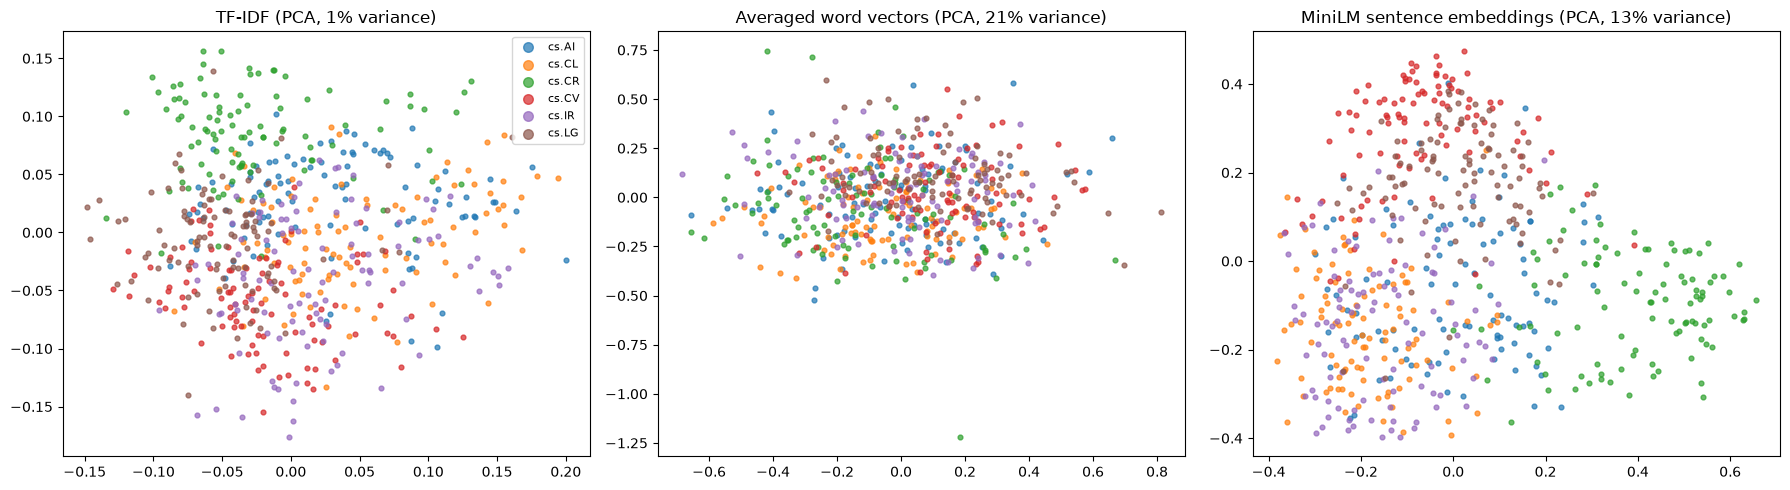

In [6]:
viz = index_df.groupby("primary_category", group_keys=False).sample(n=100, random_state=SEED)
viz_rows = viz.index.values
spaces = {"TF-IDF": X_tfidf_index[viz_rows].toarray(),
          "Averaged word vectors": X_w2v_index[viz_rows],
          "MiniLM sentence embeddings": X_st_index[viz_rows]}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
explained = {}
for ax, (name, X) in zip(axes, spaces.items()):
    pca = PCA(n_components=2, random_state=SEED)
    pts = pca.fit_transform(X)
    explained[name] = round(float(pca.explained_variance_ratio_.sum()), 3)
    for cat in CATEGORIES:
        m = (viz["primary_category"] == cat).values
        ax.scatter(pts[m, 0], pts[m, 1], s=12, label=cat, alpha=0.7)
    ax.set_title(f"{name} (PCA, {explained[name]:.0%} variance)")
axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()
results["pca_variance_explained"] = explained

## Cosine-similarity retrieval (W4) and evaluation: P@5 and nDCG@5

For every query paper, rank all 9,600 index papers by cosine similarity. **P@5** = share of the top-5 with the query's category; **nDCG@5** also rewards putting relevant papers higher. Random guessing gives P@5 ≈ 1/6 = 0.167.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** P@5 and nDCG@5 with same-category relevance are the standard retrieval metrics and the only ones the metadata supports (no citations, no click data). 200 held-out queries give stable means; the random baseline (1/6) anchors the scale.


In [7]:
def precision_at_k(ranked_cats, query_cat, k=K):
    return float(np.mean(ranked_cats[:k] == query_cat))


def ndcg_at_k(ranked_cats, query_cat, k=K):
    gains = (ranked_cats[:k] == query_cat).astype(float)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    ideal = discounts[:k].sum()                      # every top-k paper relevant
    return float((gains * discounts).sum() / ideal)


def evaluate_retriever(name, sim_matrix):
    """sim_matrix: (n_queries, n_index). Returns mean P@5 / nDCG@5 over the 200 queries."""
    p, n = [], []
    for qi, qcat in enumerate(query_df["primary_category"]):
        order = np.argsort(-sim_matrix[qi])[:K]
        ranked = index_cats[order]
        p.append(precision_at_k(ranked, qcat))
        n.append(ndcg_at_k(ranked, qcat))
    return {"retriever": name, "P@5": round(float(np.mean(p)), 3), "nDCG@5": round(float(np.mean(n)), 3)}


t0 = time.time()
sims = {
    "TF-IDF (1-2 grams)": cosine_similarity(X_tfidf_query, X_tfidf_index),
    "Averaged word vectors": cosine_similarity(X_w2v_query, X_w2v_index),
    "MiniLM sentence embeddings": X_st_query @ X_st_index.T,      # already L2-normalised
}
retrieval_table = pd.DataFrame([evaluate_retriever(n, s) for n, s in sims.items()]).set_index("retriever")
retrieval_table.loc["random baseline"] = [round(1 / len(CATEGORIES), 3), round(1 / len(CATEGORIES), 3)]
results["retrieval_eval"] = retrieval_table.reset_index().to_dict(orient="records")
print(f"{time.time() - t0:.0f} s")
retrieval_table

0 s


,P@5,nDCG@5
retriever,,
TF-IDF (1-2 grams),0.619,0.636
Averaged word vectors,0.420,0.420
MiniLM sentence embeddings,0.704,0.708
random baseline,0.167,0.167


In [8]:
# The same query under the three retrievers, to read by hand
qi = 0
print("QUERY:", query_df.loc[qi, "primary_category"], "|", query_df.loc[qi, "title"], "\n")
for name, s in sims.items():
    order = np.argsort(-s[qi])[:K]
    print(name)
    for r in order:
        print(f"   {s[qi, r]:.3f}  [{index_cats[r]}] {index_df.loc[r, 'title'][:90]}")
    print()

QUERY: cs.CR | The Right to be Forgotten in Federated Learning: An Efficient Realization with Rapid Retraining 

TF-IDF (1-2 grams)
   0.183  [cs.IR] Forgetting Fast in Recommender Systems
   0.175  [cs.CL] Deep Contrastive Unlearning for Language Models
   0.158  [cs.CR] TAPE: Tailored Posterior Difference for Auditing of Machine Unlearning
   0.139  [cs.CR] Efficient Federated Unlearning under Plausible Deniability
   0.130  [cs.LG] Image Feature Fusion-based Federated Client Unlearning (FCU)

Averaged word vectors
   0.988  [cs.LG] Fast Machine Unlearning Without Retraining Through Selective Synaptic Dampening
   0.986  [cs.CL] Benchmarking LLMs for Pairwise Causal Discovery in Biomedical and Multi-Domain Contexts
   0.986  [cs.LG] Explainable Recommender Systems via Resolving Learning Representations
   0.986  [cs.IR] Forgetting Fast in Recommender Systems
   0.986  [cs.IR] How to Retrain Recommender System? A Sequential Meta-Learning Method

MiniLM sentence embeddings
   0.765  [c

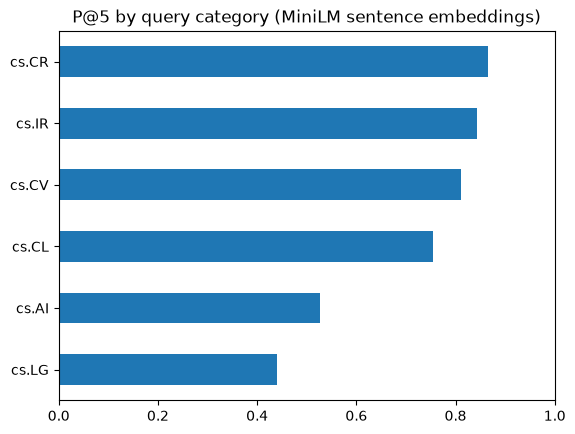

In [9]:
# Per-category P@5 for the best retriever: which domains are easy / hard to retrieve?
best_name = retrieval_table.drop("random baseline")["nDCG@5"].idxmax()
per_cat = {}
for qi, qcat in enumerate(query_df["primary_category"]):
    order = np.argsort(-sims[best_name][qi])[:K]
    per_cat.setdefault(qcat, []).append(precision_at_k(index_cats[order], qcat))
per_cat = pd.Series({c: round(float(np.mean(v)), 3) for c, v in per_cat.items()}).sort_values()
results["best_retriever"] = best_name
results["p_at_5_by_category"] = per_cat.to_dict()
per_cat.plot.barh(title=f"P@5 by query category ({best_name})", xlim=(0, 1))
plt.show()

## Clustering (W4 text clustering): KMeans, k = 6

Unsupervised check of the same spaces: KMeans with k = 6 on the training papers. **Purity** = each cluster is credited with its majority category; **adjusted Rand index** corrects for chance. The top TF-IDF terms per MiniLM cluster show what the clusters mean.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** KMeans (Week 4 text clustering) asks whether the six domains emerge without labels; purity and adjusted Rand index make the three spaces comparable. The cluster-term table is also the "topic discovery" feature of the system: a cluster's top terms describe a research area.


In [10]:
def purity(labels, clusters):
    ct = pd.crosstab(clusters, labels)
    return float(ct.max(axis=1).sum() / ct.values.sum())


cluster_rows = []
cluster_assignments = {}
for name, X in {"TF-IDF (SVD-100)": None, "Averaged word vectors": X_w2v_index, "MiniLM sentence embeddings": X_st_index}.items():
    if X is None:
        from sklearn.decomposition import TruncatedSVD
        X = TruncatedSVD(n_components=100, random_state=SEED).fit_transform(X_tfidf_index)   # KMeans on 17k sparse dims is slow and poor
    km = KMeans(n_clusters=len(CATEGORIES), n_init=10, random_state=SEED).fit(X)
    cluster_assignments[name] = km.labels_
    cluster_rows.append({"space": name, "purity": round(purity(index_cats, km.labels_), 3),
                         "adjusted_rand": round(adjusted_rand_score(index_cats, km.labels_), 3)})
cluster_table = pd.DataFrame(cluster_rows).set_index("space")
results["clustering"] = cluster_table.reset_index().to_dict(orient="records")
cluster_table

,purity,adjusted_rand
space,,
TF-IDF (SVD-100),0.572,0.263
Averaged word vectors,0.296,0.046
MiniLM sentence embeddings,0.727,0.484


In [11]:
# What is in each MiniLM cluster: majority category + top TF-IDF terms
labels = cluster_assignments["MiniLM sentence embeddings"]
terms = tfidf.get_feature_names_out()
rows = []
for c in range(len(CATEGORIES)):
    members = np.where(labels == c)[0]
    majority = pd.Series(index_cats[members]).value_counts()
    mean_w = np.asarray(X_tfidf_index[members].mean(axis=0)).ravel()
    rows.append({"cluster": c, "papers": len(members),
                 "majority": f"{majority.index[0]} ({majority.iloc[0] / len(members):.0%})",
                 "top terms": ", ".join(terms[j] for j in np.argsort(-mean_w)[:8])})
cluster_terms = pd.DataFrame(rows).set_index("cluster")
results["minilm_cluster_terms"] = cluster_terms.reset_index().to_dict(orient="records")
pd.set_option("display.max_colwidth", 120)
cluster_terms

,papers,majority,top terms
cluster,,,
0,1620,cs.LG (67%),"learning, data, neural, networks, model, deep, training, models"
1,915,cs.IR (92%),"recommendation, user, recommender, item, recommender systems, users, items, systems"
2,2260,cs.CL (56%),"language, models, retrieval, text, model, language models, large, llms"
3,1597,cs.AI (63%),"reasoning, agent, agents, learning, models, reinforcement, model, ai"
4,1648,cs.CR (89%),"security, attacks, privacy, attack, data, based, paper, secure"
5,1560,cs.CV (84%),"image, images, 3d, visual, object, video, model, models"


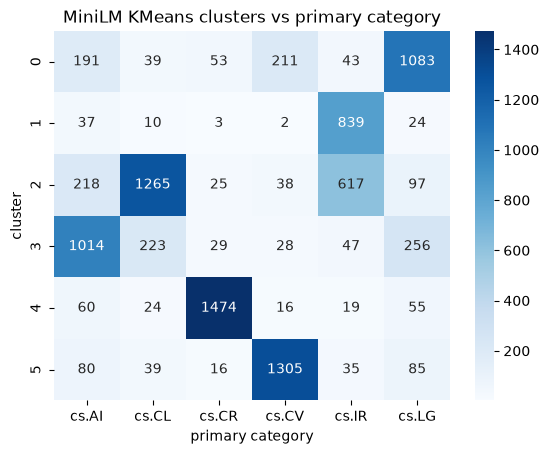

In [12]:
sns.heatmap(pd.crosstab(labels, index_cats), annot=True, fmt="d", cmap="Blues")
plt.title("MiniLM KMeans clusters vs primary category")
plt.xlabel("primary category")
plt.ylabel("cluster")
plt.show()

## RAG retriever for the system (W12): `retrieval.retrieve` and `retrieval.recommend`

`codes/retrieval.py` wraps the MiniLM index over **all 12,000 papers** (not just training) so the demo can find any paper. `utils.retrieve` picks it up automatically, which is what notebooks 05 and 06 call. `recommend(paper_id)` returns the nearest papers to a given paper, excluding itself — the "recommend relevant papers" part of the use case.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** The deployed retriever (Week 12 RAG) indexes all 12k papers once and answers in milliseconds, so the LLM in notebooks 05/06 always receives real abstracts to ground its answers. `recommend()` reuses the same index for paper-to-paper recommendation, which is the use case's final requirement.


In [13]:
from utils import retrieve                      # routed to retrieval.retrieve now that retrieval.py exists

for q in ["prompt injection attacks on large language models",
          "sequential recommendation with self-attention"]:
    t0 = time.time()
    hits = retrieve(q, k=K)
    print(f"QUERY: {q}   ({(time.time() - t0) * 1000:.0f} ms)")
    for _, h in hits.iterrows():
        print(f"   {h['score']:.3f} [{h['primary_category']}] {h['title'][:90]}")
    print()

QUERY: prompt injection attacks on large language models   (775 ms)
   0.759 [cs.CR] An Early Categorization of Prompt Injection Attacks on Large Language Models
   0.755 [cs.CR] May I have your Attention? Breaking Fine-Tuning based Prompt Injection Defenses using Arch
   0.704 [cs.CR] Ignore This Title and HackAPrompt: Exposing Systemic Vulnerabilities of LLMs through a Glo
   0.682 [cs.CR] AEGIS : Automated Co-Evolutionary Framework for Guarding Prompt Injections Schema
   0.662 [cs.CR] ELBA-Bench: An Efficient Learning Backdoor Attacks Benchmark for Large Language Models

QUERY: sequential recommendation with self-attention   (28 ms)
   0.715 [cs.IR] Lightweight Self-Attentive Sequential Recommendation
   0.711 [cs.IR] Denoising Self-attentive Sequential Recommendation
   0.648 [cs.IR] Cold-start Sequential Recommendation via Meta Learner
   0.646 [cs.IR] A Contextual-Aware Position Encoding for Sequential Recommendation
   0.645 [cs.IR] Intent-aware Diffusion with Contrastive Learn

In [14]:
seed_paper = query_df.iloc[1]
print("SEED PAPER:", f"[{seed_paper['primary_category']}]", seed_paper["title"], "\n")
recs = retrieval.recommend(seed_paper["id"], k=K)
recs[["score", "primary_category", "title"]]

SEED PAPER: [cs.IR] Sequential Recommendation via Stochastic Self-Attention 



,score,primary_category,title
0,0.672421,cs.IR,Contrastive Learning for Sequential Recommendation
1,0.667414,cs.IR,Intent-aware Diffusion with Contrastive Learning for Sequential Recommendation
2,0.664944,cs.IR,Denoising Self-attentive Sequential Recommendation
3,0.649427,cs.IR,Debiased Contrastive Learning for Sequential Recommendation
4,0.646146,cs.IR,Enhancing guidance for missing data in diffusion-based sequential recommendation


In [15]:
# Latency of the deployed retriever (what the demo and the report quote)
t0 = time.time()
for q in query_df["title"].head(50):
    retrieve(q, k=K)
results["retrieve_latency_ms"] = round((time.time() - t0) / 50 * 1000, 1)
print("mean retrieve() latency:", results["retrieve_latency_ms"], "ms (includes query encoding)")

mean retrieve() latency: 10.0 ms (includes query encoding)


## Findings and limitations

> **Owner, 2-4 lines each, from the numbers above:**
> - Which representation retrieves best (P@5 / nDCG@5) and by how much over TF-IDF; whether averaged word vectors sit between them and why (they lose word order and are dominated by frequent words).
> - What the PCA plots and cluster purity say: do unsupervised clusters recover the six arXiv domains, and which domains merge (compare with notebook 03's confusion pairs).
> - Limitations: same-category relevance is a proxy (a cross-listed cs.AI/cs.LG paper counts as a miss for one of them); MiniLM is trained on general text, not scientific; no citation data, so "related work" is similarity-based only.

In [16]:
path = save_results("04", results)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent))
retrieval_table

Saved artifacts\04_results.json


,P@5,nDCG@5
retriever,,
TF-IDF (1-2 grams),0.619,0.636
Averaged word vectors,0.420,0.420
MiniLM sentence embeddings,0.704,0.708
random baseline,0.167,0.167
